In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('/content/sample_data/covid_19_india.csv')

print("Dataset Loaded Successfully")

Saving covid_19_india.csv to covid_19_india.csv
Dataset Loaded Successfully


In [3]:
#display first 5 rows
df.head()

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1
1,2,2020-01-31,6:00 PM,Kerala,1,0,0,0,1
2,3,2020-02-01,6:00 PM,Kerala,2,0,0,0,2
3,4,2020-02-02,6:00 PM,Kerala,3,0,0,0,3
4,5,2020-02-03,6:00 PM,Kerala,3,0,0,0,3


In [4]:
#check dataset size
print("Rows and Columns:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Rows and Columns: (18110, 9)
Total Rows: 18110
Total Columns: 9


In [5]:
#Check Column Names
print(df.columns)

Index(['Sno', 'Date', 'Time', 'State/UnionTerritory',
       'ConfirmedIndianNational', 'ConfirmedForeignNational', 'Cured',
       'Deaths', 'Confirmed'],
      dtype='object')


In [6]:
#Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Sno                       18110 non-null  int64 
 1   Date                      18110 non-null  object
 2   Time                      18110 non-null  object
 3   State/UnionTerritory      18110 non-null  object
 4   ConfirmedIndianNational   18110 non-null  object
 5   ConfirmedForeignNational  18110 non-null  object
 6   Cured                     18110 non-null  int64 
 7   Deaths                    18110 non-null  int64 
 8   Confirmed                 18110 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.2+ MB


In [7]:
#Statical Summary
df.describe()

,Sno,Cured,Deaths,Confirmed
count,18110.000000,1.811000e+04,18110.000000,1.811000e+04
mean,9055.500000,2.786375e+05,4052.402264,3.010314e+05
std,5228.051023,6.148909e+05,10919.076411,6.561489e+05
min,1.000000,0.000000e+00,0.000000,0.000000e+00
25%,4528.250000,3.360250e+03,32.000000,4.376750e+03
50%,9055.500000,3.336400e+04,588.000000,3.977350e+04
75%,13582.750000,2.788698e+05,3643.750000,3.001498e+05
max,18110.000000,6.159676e+06,134201.000000,6.363442e+06


In [8]:
#Check missing values(missing values are empty or unavailable values in a dataset.We use isnull() to identify missing values.)
df.isnull().sum()

,0
Sno,0
Date,0
Time,0
State/UnionTerritory,0
ConfirmedIndianNational,0
ConfirmedForeignNational,0
Cured,0
Deaths,0
Confirmed,0


In [9]:
#cehck duplicates records
print("total duplicate rows:",
df.duplicated().sum())

total duplicate rows: 0


In [10]:
#check datasets
df.dtypes


,0
Sno,int64
Date,object
Time,object
State/UnionTerritory,object
ConfirmedIndianNational,object
ConfirmedForeignNational,object
Cured,int64
Deaths,int64
Confirmed,int64


In [15]:
#convert data column
df['Date'] =pd.to_datetime(df['Date'])
print(df['Date'].dtype)

datetime64[ns]


In [16]:
#check special values
print(df['ConfirmedIndianNational'].value_counts())
print(df['ConfirmedForeignNational'].value_counts())

ConfirmedIndianNational
-      17664
1        108
3         73
2         33
4         21
       ...  
127        1
177        1
52         1
46         1
54         1
Name: count, Length: 62, dtype: int64
ConfirmedForeignNational
-     17664
0       314
1        39
2        36
14       25
3        12
10        6
8         5
7         3
6         3
11        2
9         1
Name: count, dtype: int64


In [17]:
#replace '-' with NAN
df.replace('-', np.nan, inplace=True)

print(df.isnull().sum())

Sno                             0
Date                            0
Time                            0
State/UnionTerritory            0
ConfirmedIndianNational     17664
ConfirmedForeignNational    17664
Cured                           0
Deaths                          0
Confirmed                       0
dtype: int64


In [18]:
#convert columns into numerical format
df['ConfirmedIndianNational'] = pd.to_numeric(
    df['ConfirmedIndianNational']
)

df['ConfirmedForeignNational'] = pd.to_numeric(
    df['ConfirmedForeignNational']
)

print(df.dtypes)

Sno                                  int64
Date                        datetime64[ns]
Time                                object
State/UnionTerritory                object
ConfirmedIndianNational            float64
ConfirmedForeignNational           float64
Cured                                int64
Deaths                               int64
Confirmed                            int64
dtype: object


In [21]:
#checking missing values percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Sno                          0.000000
Date                         0.000000
Time                         0.000000
State/UnionTerritory         0.000000
ConfirmedIndianNational     97.537272
ConfirmedForeignNational    97.537272
Cured                        0.000000
Deaths                       0.000000
Confirmed                    0.000000
dtype: float64


In [22]:
#drop unnecessary columns
df.drop(
    columns=['ConfirmedIndianNational',
             'ConfirmedForeignNational'],
    inplace=True
)

print(df.columns)

Index(['Sno', 'Date', 'Time', 'State/UnionTerritory', 'Cured', 'Deaths',
       'Confirmed'],
      dtype='object')


In [23]:
#verified cleaned dataset
print("Dataset Shape:", df.shape)
print("Missing Values:")
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())


Dataset Shape: (18110, 7)
Missing Values:
Sno                     0
Date                    0
Time                    0
State/UnionTerritory    0
Cured                   0
Deaths                  0
Confirmed               0
dtype: int64
Duplicate Rows: 0


In [24]:
#save cleaned dataset
df.to_csv('covid_19_india_cleaned.csv', index=False)

print("Cleaned Dataset Saved Successfully")

Cleaned Dataset Saved Successfully


In [25]:
from google.colab import files

files.download('covid_19_india_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
#Exploratory Data Analysis (EDA)
#create basic summary
print("Total Confirmed Cases:", df['Confirmed'].sum())
print("Total Cured Cases:", df['Cured'].sum())
print("Total Deaths:", df['Deaths'].sum())

Total Confirmed Cases: 5451678687
Total Cured Cases: 5046125452
Total Deaths: 73389005


In [27]:
#Calculate recovery and death retes
total_confirmed = df['Confirmed'].sum()
total_cured = df['Cured'].sum()
total_deaths = df['Deaths'].sum()

recovery_rate = (total_cured / total_confirmed) * 100
death_rate = (total_deaths / total_confirmed) * 100

print("Recovery Rate:", round(recovery_rate, 2), "%")
print("Death Rate:", round(death_rate, 2), "%")

Recovery Rate: 92.56 %
Death Rate: 1.35 %


In [28]:
#find stste-wise confirmed cases
state_cases = df.groupby('State/UnionTerritory')['Confirmed'].max()

state_cases = state_cases.sort_values(ascending=False)

print(state_cases.head(10))

State/UnionTerritory
Maharashtra       6363442
Maharashtra***    6229596
Kerala            3586693
Karnataka         2921049
Karanataka        2885238
Tamil Nadu        2579130
Andhra Pradesh    1985182
Uttar Pradesh     1708812
West Bengal       1534999
Delhi             1436852
Name: Confirmed, dtype: int64


In [29]:
#find highest effectes cases
print("Highest Affected State:",
      state_cases.idxmax())

print("Confirmed Cases:",
      state_cases.max())

Highest Affected State: Maharashtra
Confirmed Cases: 6363442


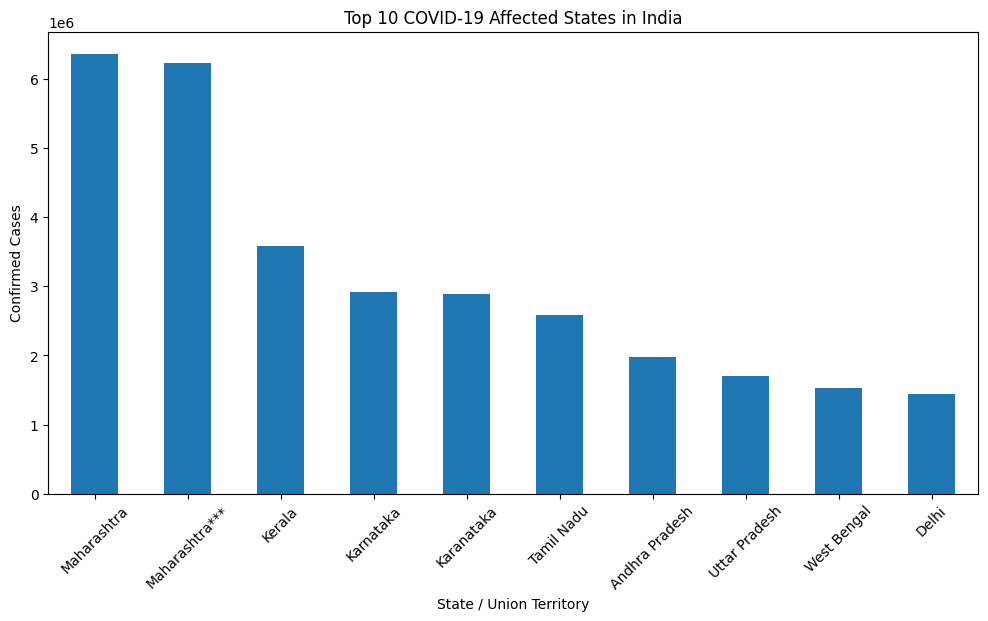

In [30]:
#Data Visualization
#Top10 most effected states bar chat
plt.figure(figsize=(12,6))

state_cases.head(10).plot(
    kind='bar',
    title='Top 10 COVID-19 Affected States in India'
)

plt.xlabel('State / Union Territory')
plt.ylabel('Confirmed Cases')
plt.xticks(rotation=45)
plt.show()


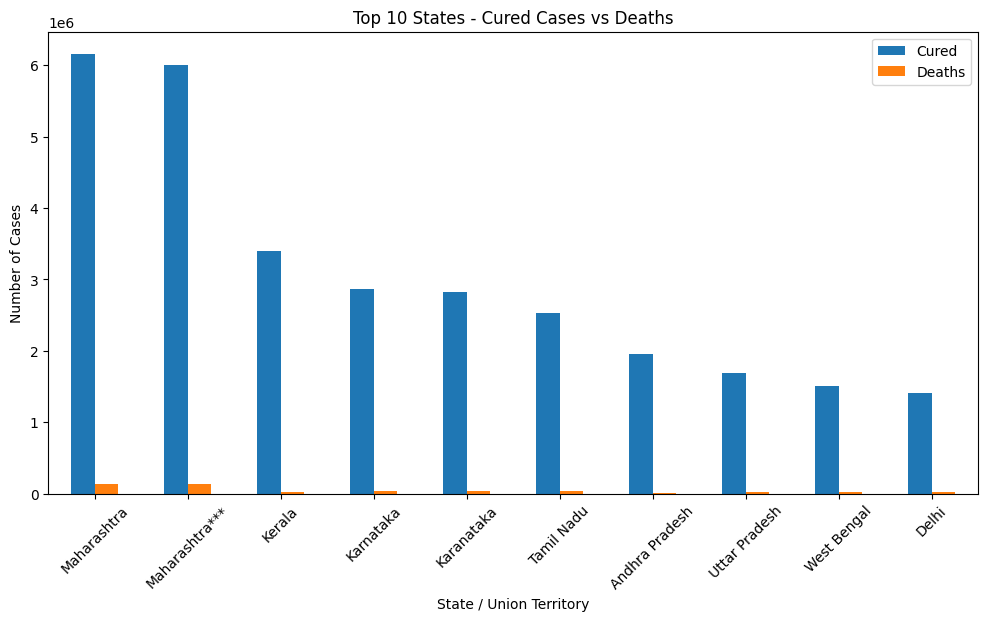

In [31]:
#Top 10 states:Cured Vs Deaths
top_states = df.groupby('State/UnionTerritory')[
    ['Cured', 'Deaths']
].max()

top_states = top_states.loc[
    state_cases.head(10).index
]

top_states.plot(
    kind='bar',
    figsize=(12,6),
    title='Top 10 States - Cured Cases vs Deaths'
)

plt.xlabel('State / Union Territory')
plt.ylabel('Number of Cases')
plt.xticks(rotation=45)
plt.legend()
plt.show()

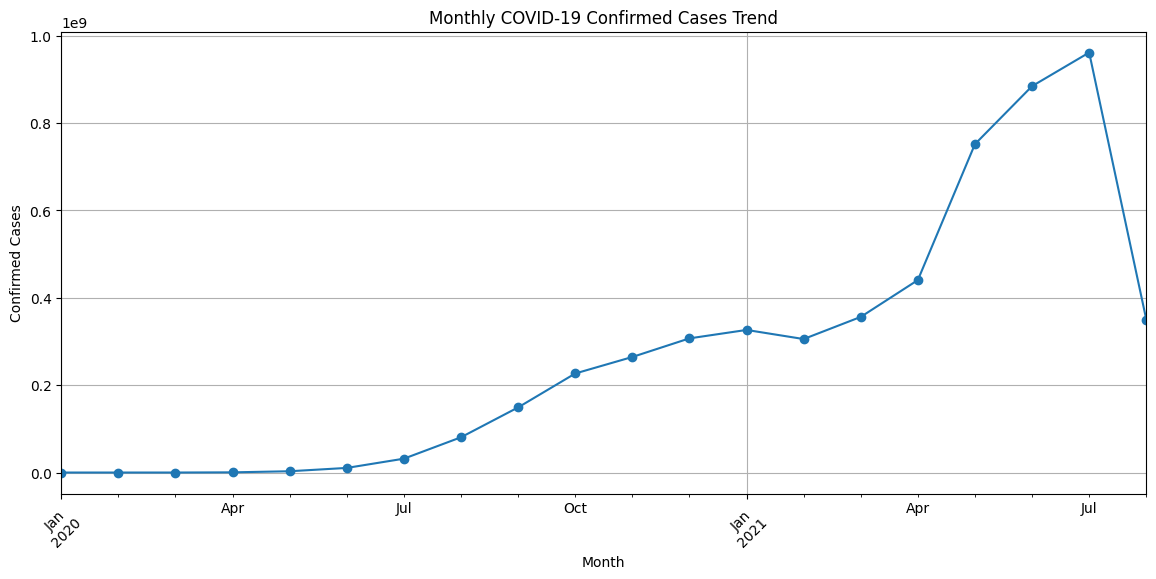

In [32]:
#Monthly Covid-19 Trend
df['Month'] = df['Date'].dt.to_period('M')

monthly_cases = df.groupby('Month')['Confirmed'].sum()

plt.figure(figsize=(14,6))

monthly_cases.plot(
    kind='line',
    marker='o',
    title='Monthly COVID-19 Confirmed Cases Trend'
)

plt.xlabel('Month')
plt.ylabel('Confirmed Cases')
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [33]:
# Calculate daily total confirmed cases
daily_cases = df.groupby('Date')['Confirmed'].sum()

# Calculate daily new cases
daily_new_cases = daily_cases.diff()

# Fill first day's missing value with 0
daily_new_cases = daily_new_cases.fillna(0)

print(daily_new_cases.head(10))

Date
2020-01-30    0.0
2020-01-31    0.0
2020-02-01    1.0
2020-02-02    1.0
2020-02-03    0.0
2020-02-04    0.0
2020-02-05    0.0
2020-02-06    0.0
2020-02-07    0.0
2020-02-08    0.0
Name: Confirmed, dtype: float64


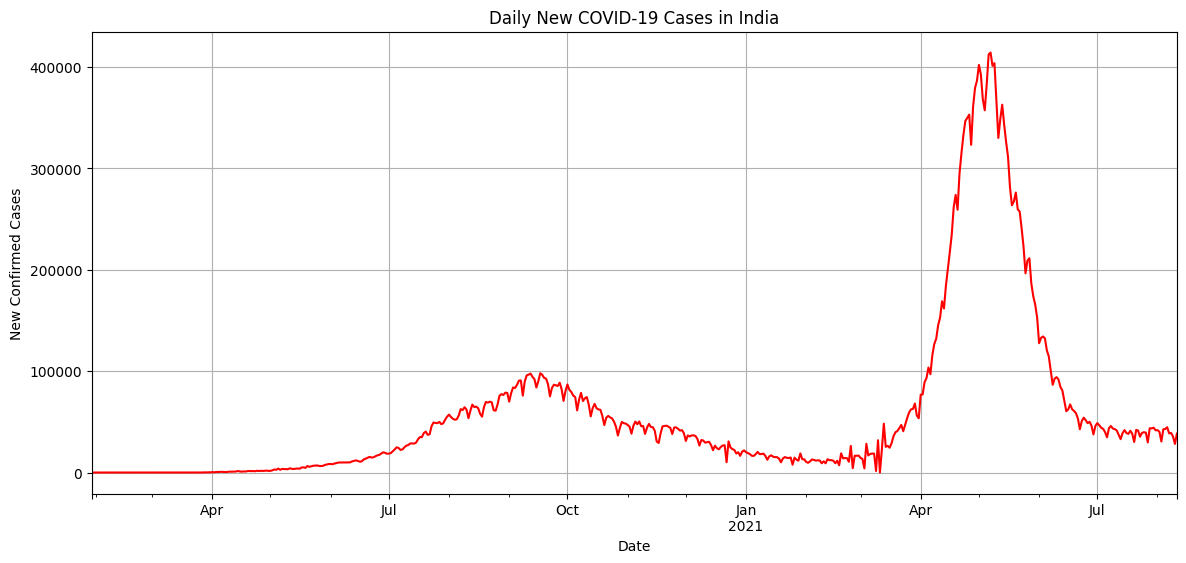

In [34]:
#dialy new cases line chart
plt.figure(figsize=(14,6))

daily_new_cases.plot(
    kind='line',
    color='red',
    title='Daily New COVID-19 Cases in India'
)

plt.xlabel('Date')
plt.ylabel('New Confirmed Cases')
plt.grid()
plt.show()

In [35]:
#dialy new deaths
daily_deaths = df.groupby('Date')['Deaths'].sum()

daily_new_deaths = daily_deaths.diff().fillna(0)

print(daily_new_deaths.head(10))

Date
2020-01-30    0.0
2020-01-31    0.0
2020-02-01    0.0
2020-02-02    0.0
2020-02-03    0.0
2020-02-04    0.0
2020-02-05    0.0
2020-02-06    0.0
2020-02-07    0.0
2020-02-08    0.0
Name: Deaths, dtype: float64


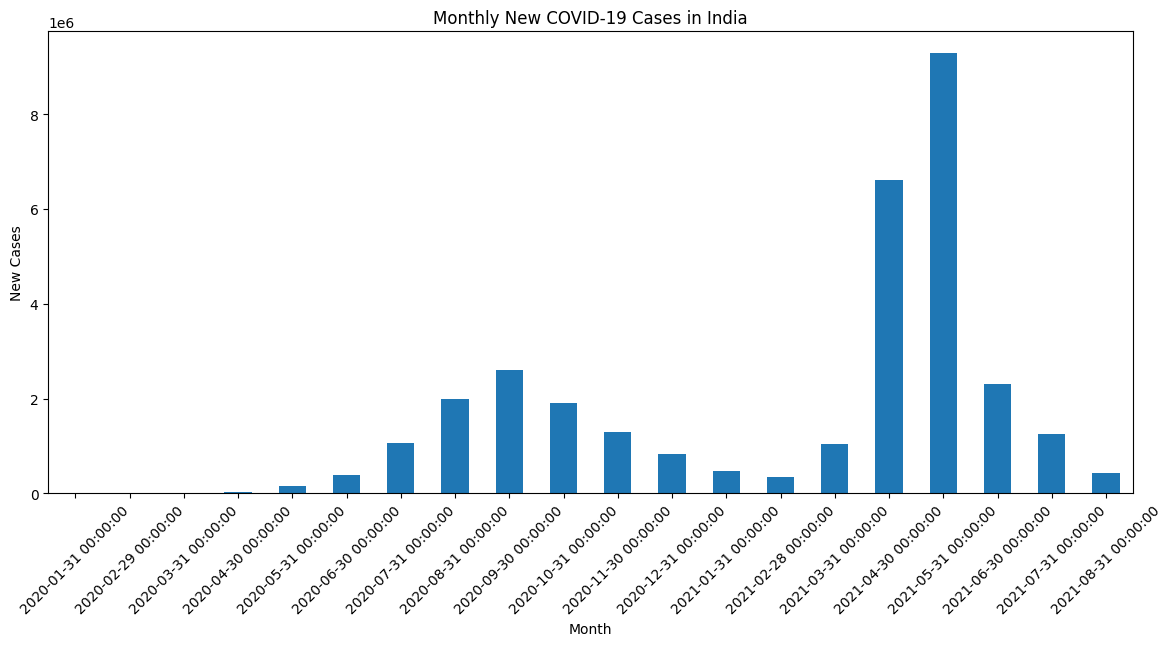

In [37]:
#dialy deaths line chart
monthly_new_cases = daily_new_cases.resample('ME').sum()

plt.figure(figsize=(14,6))

monthly_new_cases.plot(
    kind='bar',
    title='Monthly New COVID-19 Cases in India'
)

plt.xlabel('Month')
plt.ylabel('New Cases')
plt.xticks(rotation=45)
plt.show()

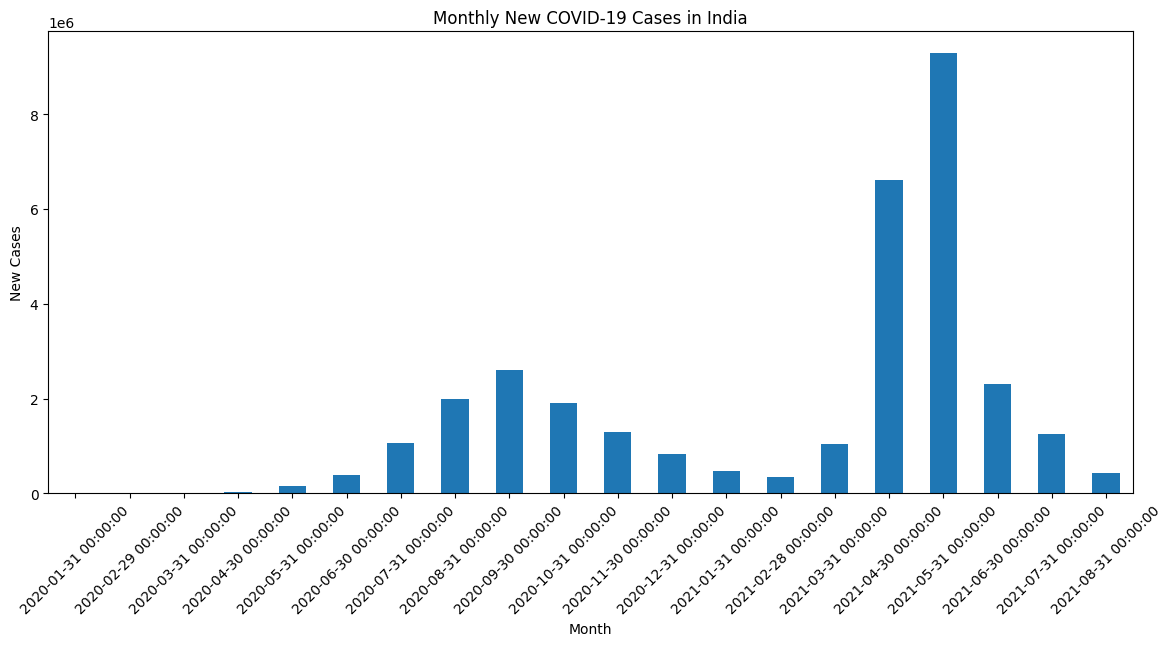

In [38]:
#monthly new cases Analysis
monthly_new_cases = daily_new_cases.resample('ME').sum()

plt.figure(figsize=(14,6))

monthly_new_cases.plot(
    kind='bar',
    title='Monthly New COVID-19 Cases in India'
)

plt.xlabel('Month')
plt.ylabel('New Cases')
plt.xticks(rotation=45)
plt.show()


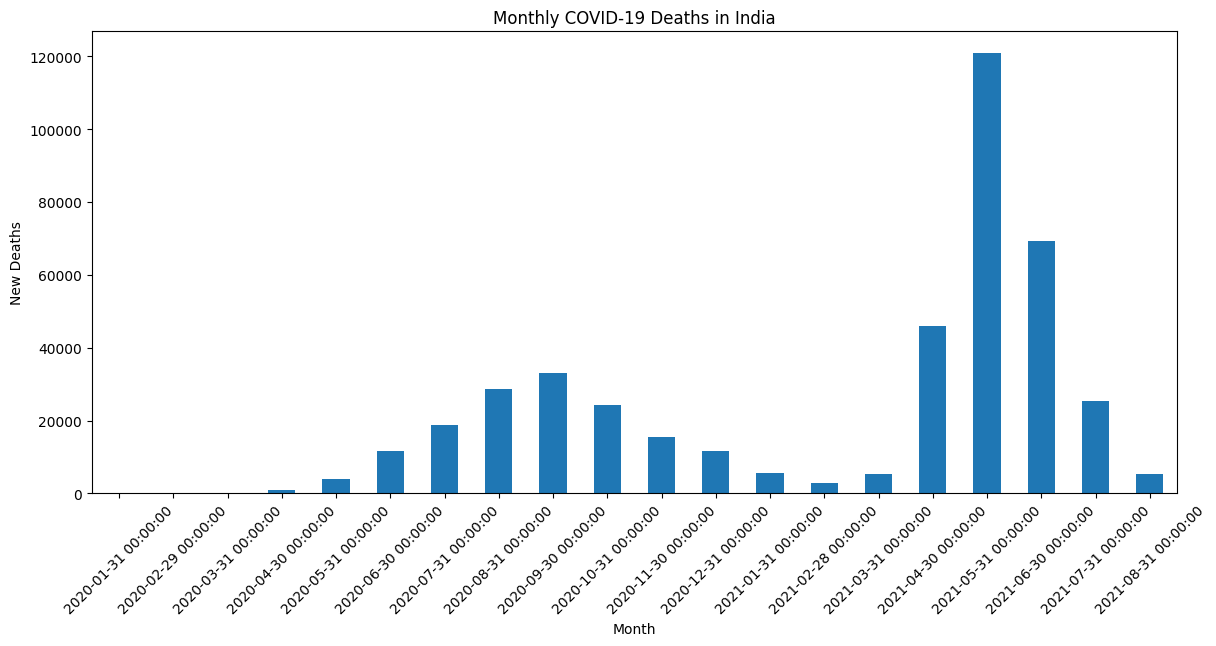

In [39]:
#mothly deaths Analysis
monthly_deaths = daily_new_deaths.resample('ME').sum()

plt.figure(figsize=(14,6))

monthly_deaths.plot(
    kind='bar',
    title='Monthly COVID-19 Deaths in India'
)

plt.xlabel('Month')
plt.ylabel('New Deaths')
plt.xticks(rotation=45)
plt.show()

State/UnionTerritory
Maharashtra       134201
Maharashtra***    130753
Karnataka          36848
Karanataka         36197
Tamil Nadu         34367
Delhi              25068
Uttar Pradesh      22775
West Bengal        18252
Kerala             18004
Punjab             16322
Name: Deaths, dtype: int64


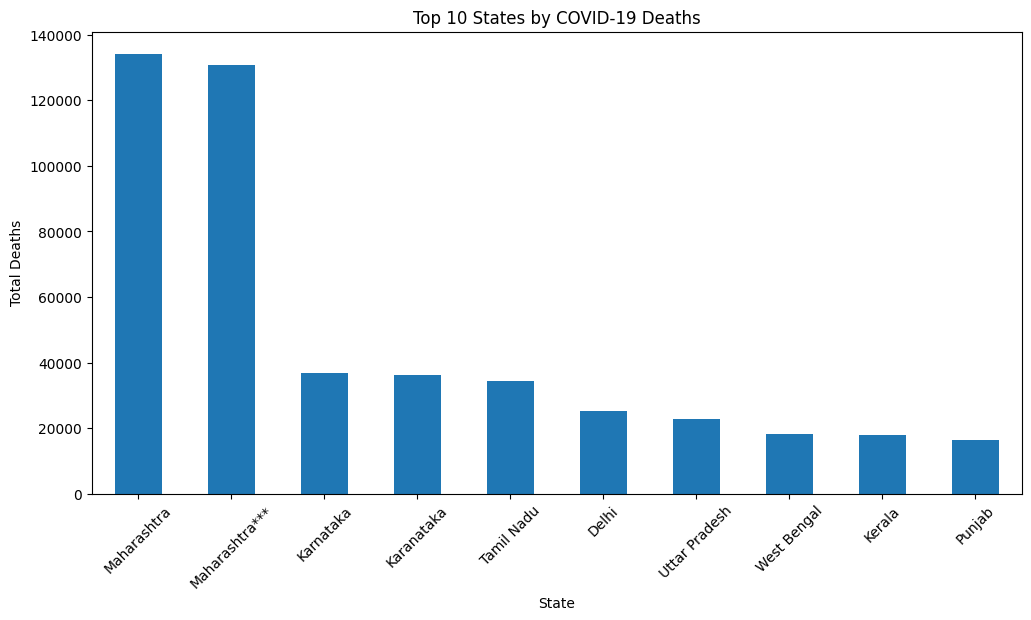

In [40]:
#Top 10 States by deaths
state_deaths = df.groupby(
    'State/UnionTerritory'
)['Deaths'].max()

top_10_deaths = state_deaths.sort_values(
    ascending=False
).head(10)

print(top_10_deaths)

top_10_deaths.plot(
    kind='bar',
    figsize=(12,6),
    title='Top 10 States by COVID-19 Deaths'
)

plt.xlabel('State')
plt.ylabel('Total Deaths')
plt.xticks(rotation=45)
plt.show()

In [41]:
#state wise recovery rate
latest_state_data = (
    df.sort_values('Date')
    .groupby('State/UnionTerritory')
    .tail(1)
    .copy()
)

latest_state_data['Recovery_Rate'] = (
    latest_state_data['Cured'] /
    latest_state_data['Confirmed']
) * 100

print(
    latest_state_data[
        ['State/UnionTerritory', 'Recovery_Rate']
    ].sort_values(
        by='Recovery_Rate',
        ascending=False
    )
)

                           State/UnionTerritory  Recovery_Rate
18081  Dadra and Nagar Haveli and Daman and Diu      99.924911
18092                               Lakshadweep      99.045114
18102                                 Rajasthan      99.040626
15669                    Dadra and Nagar Haveli      98.882143
18084                                   Gujarat      98.753704
18085                                   Haryana      98.659419
18093                            Madhya Pradesh      98.655269
18079                                Chandigarh      98.641760
18108                             Uttar Pradesh      98.635309
18078                                     Bihar      98.631285
18091                                    Ladakh      98.623291
17049                         Madhya Pradesh***      98.620487
18080                              Chhattisgarh      98.488373
18088                                 Jharkhand      98.463620
18075                            Andhra Pradesh      98

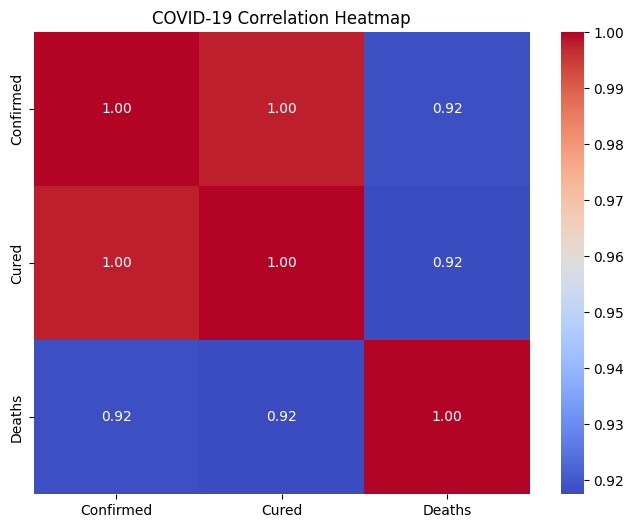

In [42]:
#Correlation heatmap
correlation = df[
    ['Confirmed', 'Cured', 'Deaths']
].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('COVID-19 Correlation Heatmap')
plt.show()

In [43]:
#Final dataset Summary
latest_date = df['Date'].max()

latest_data = df[df['Date'] == latest_date]

print("Latest Date:", latest_date)
print("Confirmed:", latest_data['Confirmed'].sum())
print("Cured:", latest_data['Cured'].sum())
print("Deaths:", latest_data['Deaths'].sum())

Latest Date: 2021-08-11 00:00:00
Confirmed: 32036511
Cured: 31220981
Deaths: 429179
